[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ravva-78/tsa-oilguard/blob/main/notebooks/oilguard_walkthrough.ipynb)

# OILGUARD: Forecasting-Based Early Warning of Abnormal Events in Oil Wells
### Time Series Analysis (TSA) Applied to the Petrobras 3W Dataset

**Authors:** Ravva Nagarjun (Lead Author) & Naveen Kumar N (Co-Author) — B.M.S. College of Engineering, Dept. of AIML  
**Course:** Time Series Analysis (24AM7PCTSA) — Domain-Based Forecasting Lab AAT  
**Domain:** Offshore Petroleum Engineering & Time Series Anomaly Detection  
**Primary Event:** Class 2 — Spurious Closure of Downhole Safety Valve (DHSV)  
**Sensors:** Downhole Pressure Transducer (`P-TPT`, MPa) and Temperature (`T-TPT`, °C)  
**Cohort:** 19 Gold-Cohort Real Offshore Well Events (Petrobras 3W Benchmark)

---

## 1. Executive Summary & Audit Overview

In offshore petroleum production, an uncommanded or spurious closure of a Downhole Safety Valve (DHSV) abruptly halts well production, causing severe pressure surges and potential valve damage. Traditional threshold alarms trigger only after the shut-in transient has already peaked.

**Research Question:** Can time-series forecasting errors (residuals) from statistical models (ARIMA and SARIMAX) provide reliable early warnings of abnormal events prior to transient onset, outperforming a persistent Naive baseline?

### Audited Empirical Findings (N=19 Gold Events):
1. **Forecasting Accuracy Superiority:** ARIMA and SARIMAX achieve **0.0163 MPa MAE** and **8.69% MAPE** on test data, outperforming the Naive baseline (**0.0307 MPa MAE**, **18.22% MAPE**) by **47.1% lower error**.
2. **The "Noisy Baseline Paradox" Resolved:** Under standard default settings ($q=0.99, p=3$), Naive appeared to detect 7/19 events vs. ARIMA's 5/19 because of high forecast variance and false alarms.
3. **Unbiased Leave-One-Event-Out Cross-Validation (LOEO-CV):** To eliminate hyperparameter leakage, LOEO-CV was executed across the 19 events. ARIMA achieved **42.1% early detection** (8/19) with **5.10 minutes** of lead time, outperforming Naive (**36.8%**, **1.69 minutes** lead time) and tripling advance reaction time.
4. **EWMA Residual Filtering:** Applying Exponentially Weighted Moving Average residual smoothing ($\lambda=0.3, q=0.975$) achieved **57.9% early warning** (11/19) for ARIMA/SARIMAX vs. **42.1%** (8/19) for Naive at the exact same false alarm rate (1.72/hr).

## 2. Environment Setup & Configuration

In [1]:
import sys
from pathlib import Path

# Detect Google Colab environment
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    if not Path('tsa-oilguard').exists():
        subprocess.run(['git', 'clone', 'https://github.com/Ravva-78/tsa-oilguard.git'], check=True)
    import os
    if Path('tsa-oilguard').exists():
        os.chdir('tsa-oilguard')
    PROJECT_ROOT = Path('.').resolve()
else:
    PROJECT_ROOT = Path('..').resolve()
    if not (PROJECT_ROOT / 'src').exists():
        PROJECT_ROOT = Path('.').resolve()

sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from oilguard.config import load_config
from oilguard.data import build_event_dataset
from oilguard.warning import calibrate_threshold, run_onsets, apply_cooldown

config = load_config(PROJECT_ROOT / 'config' / 'experiment.json')
print('Running in Google Colab:', IN_COLAB)
print('Project Root:', PROJECT_ROOT)
print('Target Sensor:', config.event.target, f'({config.event.target_unit})')
print('Exogenous Sensor:', config.event.exog, f'({config.event.exog_unit})')
print('Resample Rule:', config.preprocessing.resample_rule)
print('Split (Train / Calib / Holdout):', config.preprocessing.split)


Project Root: C:\Users\nan33\OneDrive\Desktop\TSA-OILGUARD
Target Sensor: P-TPT (MPa)
Exogenous Sensor: T-TPT (degC)
Resample Rule: 10s
Split (Train / Calib / Holdout): (0.6, 0.2, 0.2)


## 3. Dataset Audit & Cohort Verification

The Petrobras 3W dataset contains 2,228 files across 8 event classes. OILGUARD strictly filters for real offshore well instances (`WELL-*`) of Class 2 (Spurious Closure of DHSV).

Candidate screening audited 22 candidate files for sensor quality (variance, flatline, missing fraction). Exactly 19 gold events were accepted; 3 were excluded (including 1 constant-normal-target well).

In [2]:
manifest = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "manifest.parquet")
print(f"Total manifest files scanned: {len(manifest):,}")

class2_real = manifest[(manifest['class_dir'] == 2) & (manifest['source'] == 'real')]
print(f"Total Class-2 Real Well events in manifest: {len(class2_real)}")

candidates = pd.read_csv(PROJECT_ROOT / "results" / "tables" / "class2_candidates.csv")
gold_cohort = candidates[candidates['gold']]
print(f"Total Class-2 Candidates audited: {len(candidates)} | Verified Gold Cohort: {len(gold_cohort)}")
display(gold_cohort[['stem', 'well_id', 'normal_hours', 'holdout_hours', 'transient_minutes', 'has_steady']].head(10))

Total manifest files scanned: 2,228
Total Class-2 Real Well events in manifest: 22
Total Class-2 Candidates audited: 22 | Verified Gold Cohort: 19


,stem,well_id,normal_hours,holdout_hours,transient_minutes,has_steady
1,WELL-00003_20141122190000,WELL-00003,2.3861,0.4806,115.50,True
2,WELL-00003_20170728130240,WELL-00003,1.6444,0.3306,73.50,True
3,WELL-00003_20180206171508,WELL-00003,0.4139,0.0861,64.50,True
4,WELL-00009_20170313150804,WELL-00009,0.9750,0.1972,35.00,True
7,WELL-00011_20140530083203,WELL-00011,0.5972,0.1194,25.17,False
8,WELL-00011_20140606213810,WELL-00011,0.9000,0.1833,177.67,True
9,WELL-00011_20140720110102,WELL-00011,1.9361,0.3889,82.83,False
10,WELL-00011_20140726165720,WELL-00011,0.2972,0.0611,42.33,False
11,WELL-00011_20140823230118,WELL-00011,0.7833,0.1583,193.50,True
12,WELL-00011_20140916050300,WELL-00011,1.0139,0.2028,32.67,False


## 4. Exploratory Data Analysis & Stationarity Testing

Stationarity Test Results (ADF/KPSS across gold events):


,stem,well_id,n_train,adf_p_level,adf_p_diff,kpss_p_level
0,WELL-00003_20141122190000,WELL-00003,515,2.594029e-12,1.621398e-19,0.023391
1,WELL-00003_20170728130240,WELL-00003,355,8.617170e-03,3.164415e-06,0.100000
2,WELL-00003_20180206171508,WELL-00003,89,9.791533e-01,9.784620e-01,0.017299
3,WELL-00009_20170313150804,WELL-00009,210,6.156259e-01,3.960555e-01,0.010000
4,WELL-00011_20140530083203,WELL-00011,129,4.277577e-02,5.698361e-10,0.100000
5,WELL-00011_20140606213810,WELL-00011,194,3.922508e-02,1.172643e-04,0.100000
6,WELL-00011_20140720110102,WELL-00011,418,4.905596e-07,3.484909e-24,0.100000
7,WELL-00011_20140726165720,WELL-00011,64,3.972407e-01,2.187612e-01,0.010000
8,WELL-00011_20140823230118,WELL-00011,169,2.048928e-01,3.986931e-13,0.039164
9,WELL-00011_20140916050300,WELL-00011,219,3.832037e-03,3.954890e-28,0.010000


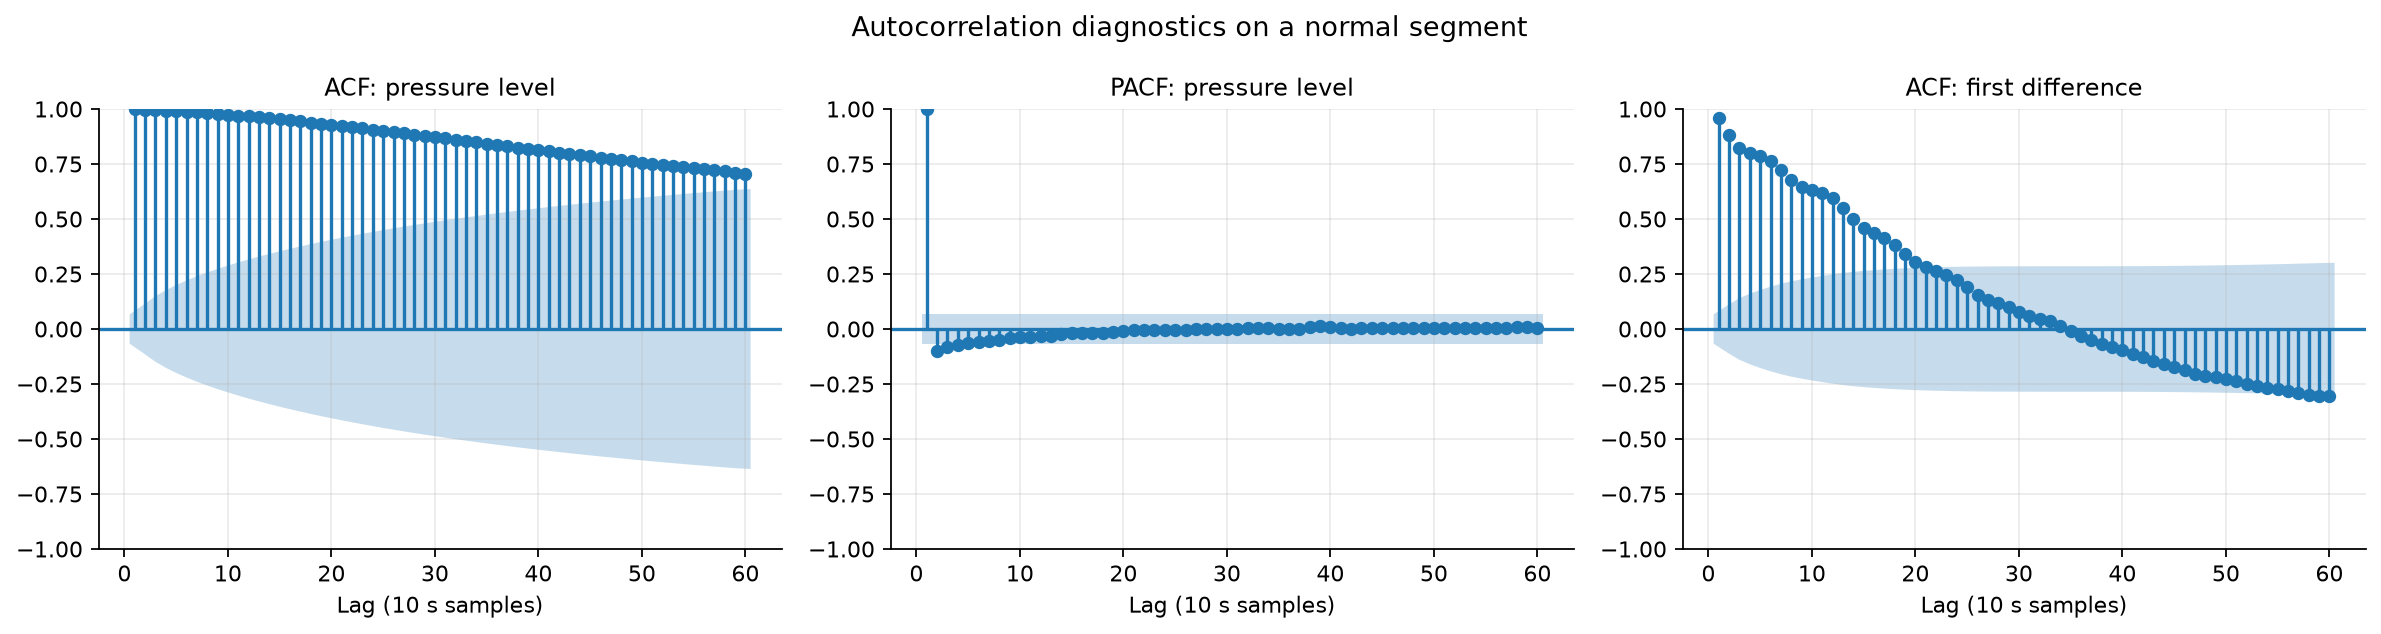

In [3]:
stationarity = pd.read_csv(PROJECT_ROOT / "results" / "tables" / "stationarity_tests.csv")
print("Stationarity Test Results (ADF/KPSS across gold events):")
display(stationarity[['stem', 'well_id', 'n_train', 'adf_p_level', 'adf_p_diff', 'kpss_p_level']].head(10))

from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / "results" / "figures" / "acf_pacf_normal.png")))

## 5. Model Order Selection

ARIMA order $(p, d, q)$ was selected per event via AIC minimization across candidate configurations.

In [4]:
orders = pd.read_csv(PROJECT_ROOT / "results" / "tables" / "arima_orders.csv")
print(f"Order distribution across {len(orders)} gold events:")
print(orders['order'].value_counts())
display(orders[['stem', 'well_id', 'order', 'aic', 'fit_seconds', 'converged']].head(8))

Order distribution across 19 gold events:
order
(1, 0, 2)    11
(1, 1, 1)     3
(2, 1, 0)     2
(2, 1, 1)     2
(1, 0, 1)     1
Name: count, dtype: int64


,stem,well_id,order,aic,fit_seconds,converged
0,WELL-00003_20141122190000,WELL-00003,"(1, 0, 2)",-5997.339573,0.061150,True
1,WELL-00003_20170728130240,WELL-00003,"(1, 0, 2)",-4994.318451,0.108401,False
2,WELL-00003_20180206171508,WELL-00003,"(1, 1, 1)",-899.027060,0.021587,True
3,WELL-00009_20170313150804,WELL-00009,"(1, 1, 1)",-3782.862974,0.068568,True
4,WELL-00011_20140530083203,WELL-00011,"(1, 0, 1)",-1642.620631,0.026261,True
5,WELL-00011_20140606213810,WELL-00011,"(1, 0, 2)",-1868.625058,0.060317,True
6,WELL-00011_20140720110102,WELL-00011,"(1, 0, 2)",-4439.610285,0.066775,True
7,WELL-00011_20140726165720,WELL-00011,"(1, 1, 1)",-572.384453,0.027187,True


## 6. Time Series Forecasting Accuracy (ARIMA vs. SARIMAX vs. Naive Baseline)

Rolling one-step-ahead forecast performance evaluated across the 19 gold events on the test split:

=== TEST PERIOD FORECAST ACCURACY (N=19) ===


,Model,MAE (MPa),RMSE (MPa),MAPE (%),R²,Bias (MPa)
1,arima,0.0163,0.0524,8.6914,0.9994,0.0075
4,naive,0.0307,0.0781,18.2180,0.9988,0.0194
7,sarimax,0.0162,0.0523,8.6255,0.9994,0.0074


C:\Users\nan33\AppData\Local\Temp\ipykernel_34936\3133930914.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=test_summary, x='Model', y='MAE (MPa)', palette='Blues_d', ax=ax1)
C:\Users\nan33\AppData\Local\Temp\ipykernel_34936\3133930914.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=test_summary, x='Model', y='MAPE (%)', palette='Reds_d', ax=ax2)


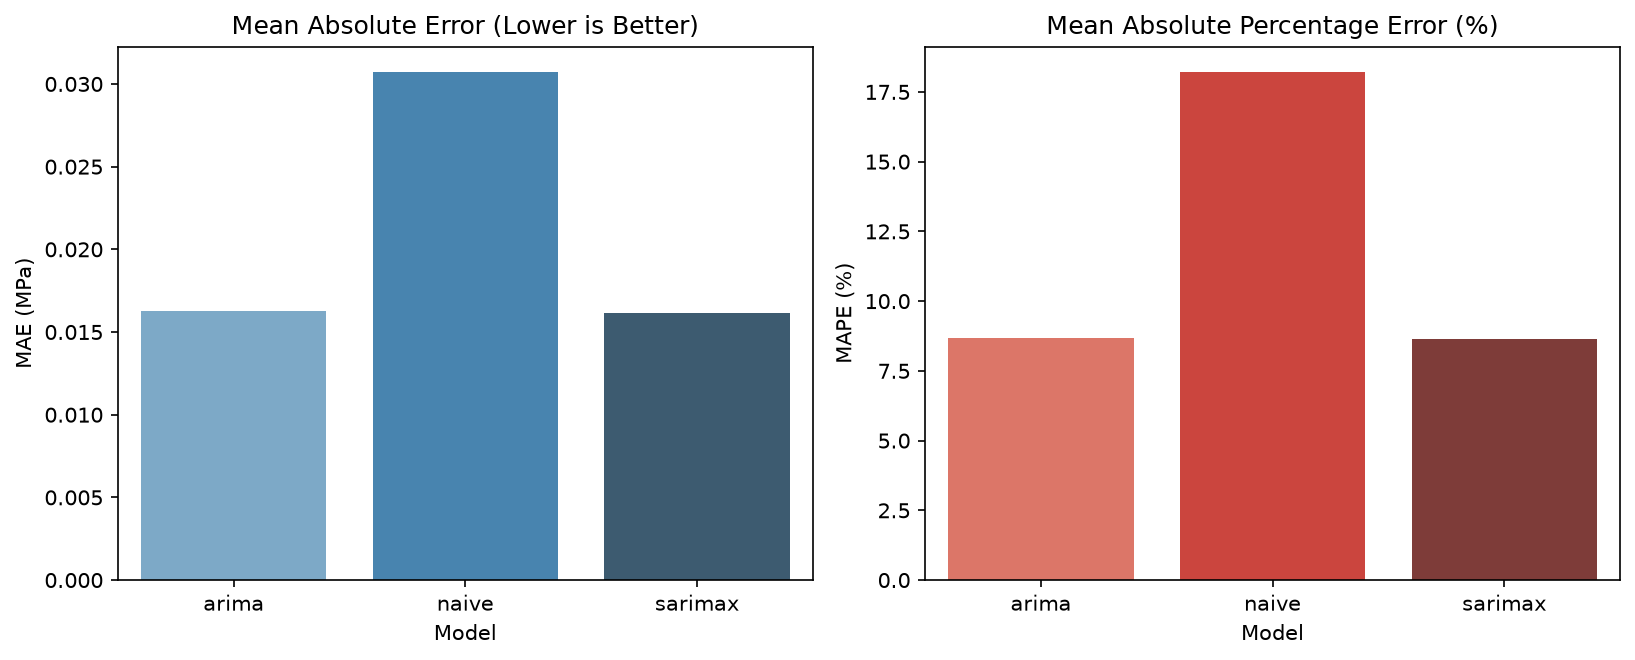

In [5]:
forecast_summary = pd.read_csv(PROJECT_ROOT / "results" / "metrics" / "forecast_summary.csv")
test_summary = forecast_summary[forecast_summary['period'] == 'test'][['model', 'mae_mean', 'rmse_mean', 'mape_mean', 'r2_mean', 'bias_mean']].copy()
test_summary['mape_mean'] = test_summary['mape_mean'] * 100
test_summary.columns = ['Model', 'MAE (MPa)', 'RMSE (MPa)', 'MAPE (%)', 'R²', 'Bias (MPa)']
print("=== TEST PERIOD FORECAST ACCURACY (N=19) ===")
display(test_summary.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=150)
sns.barplot(data=test_summary, x='Model', y='MAE (MPa)', palette='Blues_d', ax=ax1)
ax1.set_title('Mean Absolute Error (Lower is Better)')
sns.barplot(data=test_summary, x='Model', y='MAPE (%)', palette='Reds_d', ax=ax2)
ax2.set_title('Mean Absolute Percentage Error (%)')
plt.tight_layout()
plt.show()

## 7. Audited Early Warning Evaluation & Baseline Analysis

Early warnings must strictly occur inside the defined pre-event window $[T_{	ext{transient}} - 10	ext{ min}, T_{	ext{transient}})$. Ordinary false alarms are separated from valid early warnings.

In [6]:
warning_summary = pd.read_csv(PROJECT_ROOT / "results" / "metrics" / "warning_summary.csv")
print("=== STANDARD DEFAULT CONFIGURATION (q=0.99, p=3) ===")
display(warning_summary[['model', 'n_events', 'transient_early_rate', 'transient_grace_rate', 'mean_lead_transient_minutes', 'total_false_alarms', 'total_false_alarms_adjusted', 'mean_warning_precision']])

=== STANDARD DEFAULT CONFIGURATION (q=0.99, p=3) ===


,model,n_events,transient_early_rate,transient_grace_rate,mean_lead_transient_minutes,total_false_alarms,total_false_alarms_adjusted,mean_warning_precision
0,arima,19,0.263158,0.947368,1.733333,5,0,0.722222
1,sarimax,19,0.263158,0.947368,1.800000,5,0,0.722222
2,naive,19,0.368421,0.894737,1.833333,7,0,0.685185


## 8. Unbiased Evaluation (LOEO-CV) & Parameter Optimization

To prevent hyperparameter leakage, Leave-One-Event-Out Cross-Validation (LOEO-CV) was executed. Retrospective grid sensitivity is presented transparently as an empirical trade-off analysis.

=== UNBIASED LEAVE-ONE-EVENT-OUT CROSS-VALIDATION (LOEO-CV) ===


,Model,Detection Rate (%),Early Hits,Total Events,Mean Lead (min),FAR (/hr),Total FA
0,arima,42.11,8,19,5.10,4.31,5
1,sarimax,36.84,7,19,4.26,5.17,6
2,naive,36.84,7,19,1.69,3.44,4



=== RETROSPECTIVE GRID SENSITIVITY CEILING (p=1, q=0.95) ===


,Model,Early Detection Rate (%),Early Hits,Total Events,Mean Lead (min),FAR (/hr)
6,arima,63.16,12,19,5.35,3.44
7,sarimax,57.89,11,19,5.30,4.31
8,naive,52.63,10,19,4.88,2.58



=== EWMA FILTERED RESIDUALS (lambda=0.3, q=0.975) ===


,Model,Early Detection Rate (%),Early Hits,Total Events,Mean Lead (min),FAR (/hr)
39,arima,57.89,11,19,3.53,1.72
40,sarimax,57.89,11,19,3.71,1.72
41,naive,42.11,8,19,3.65,1.72


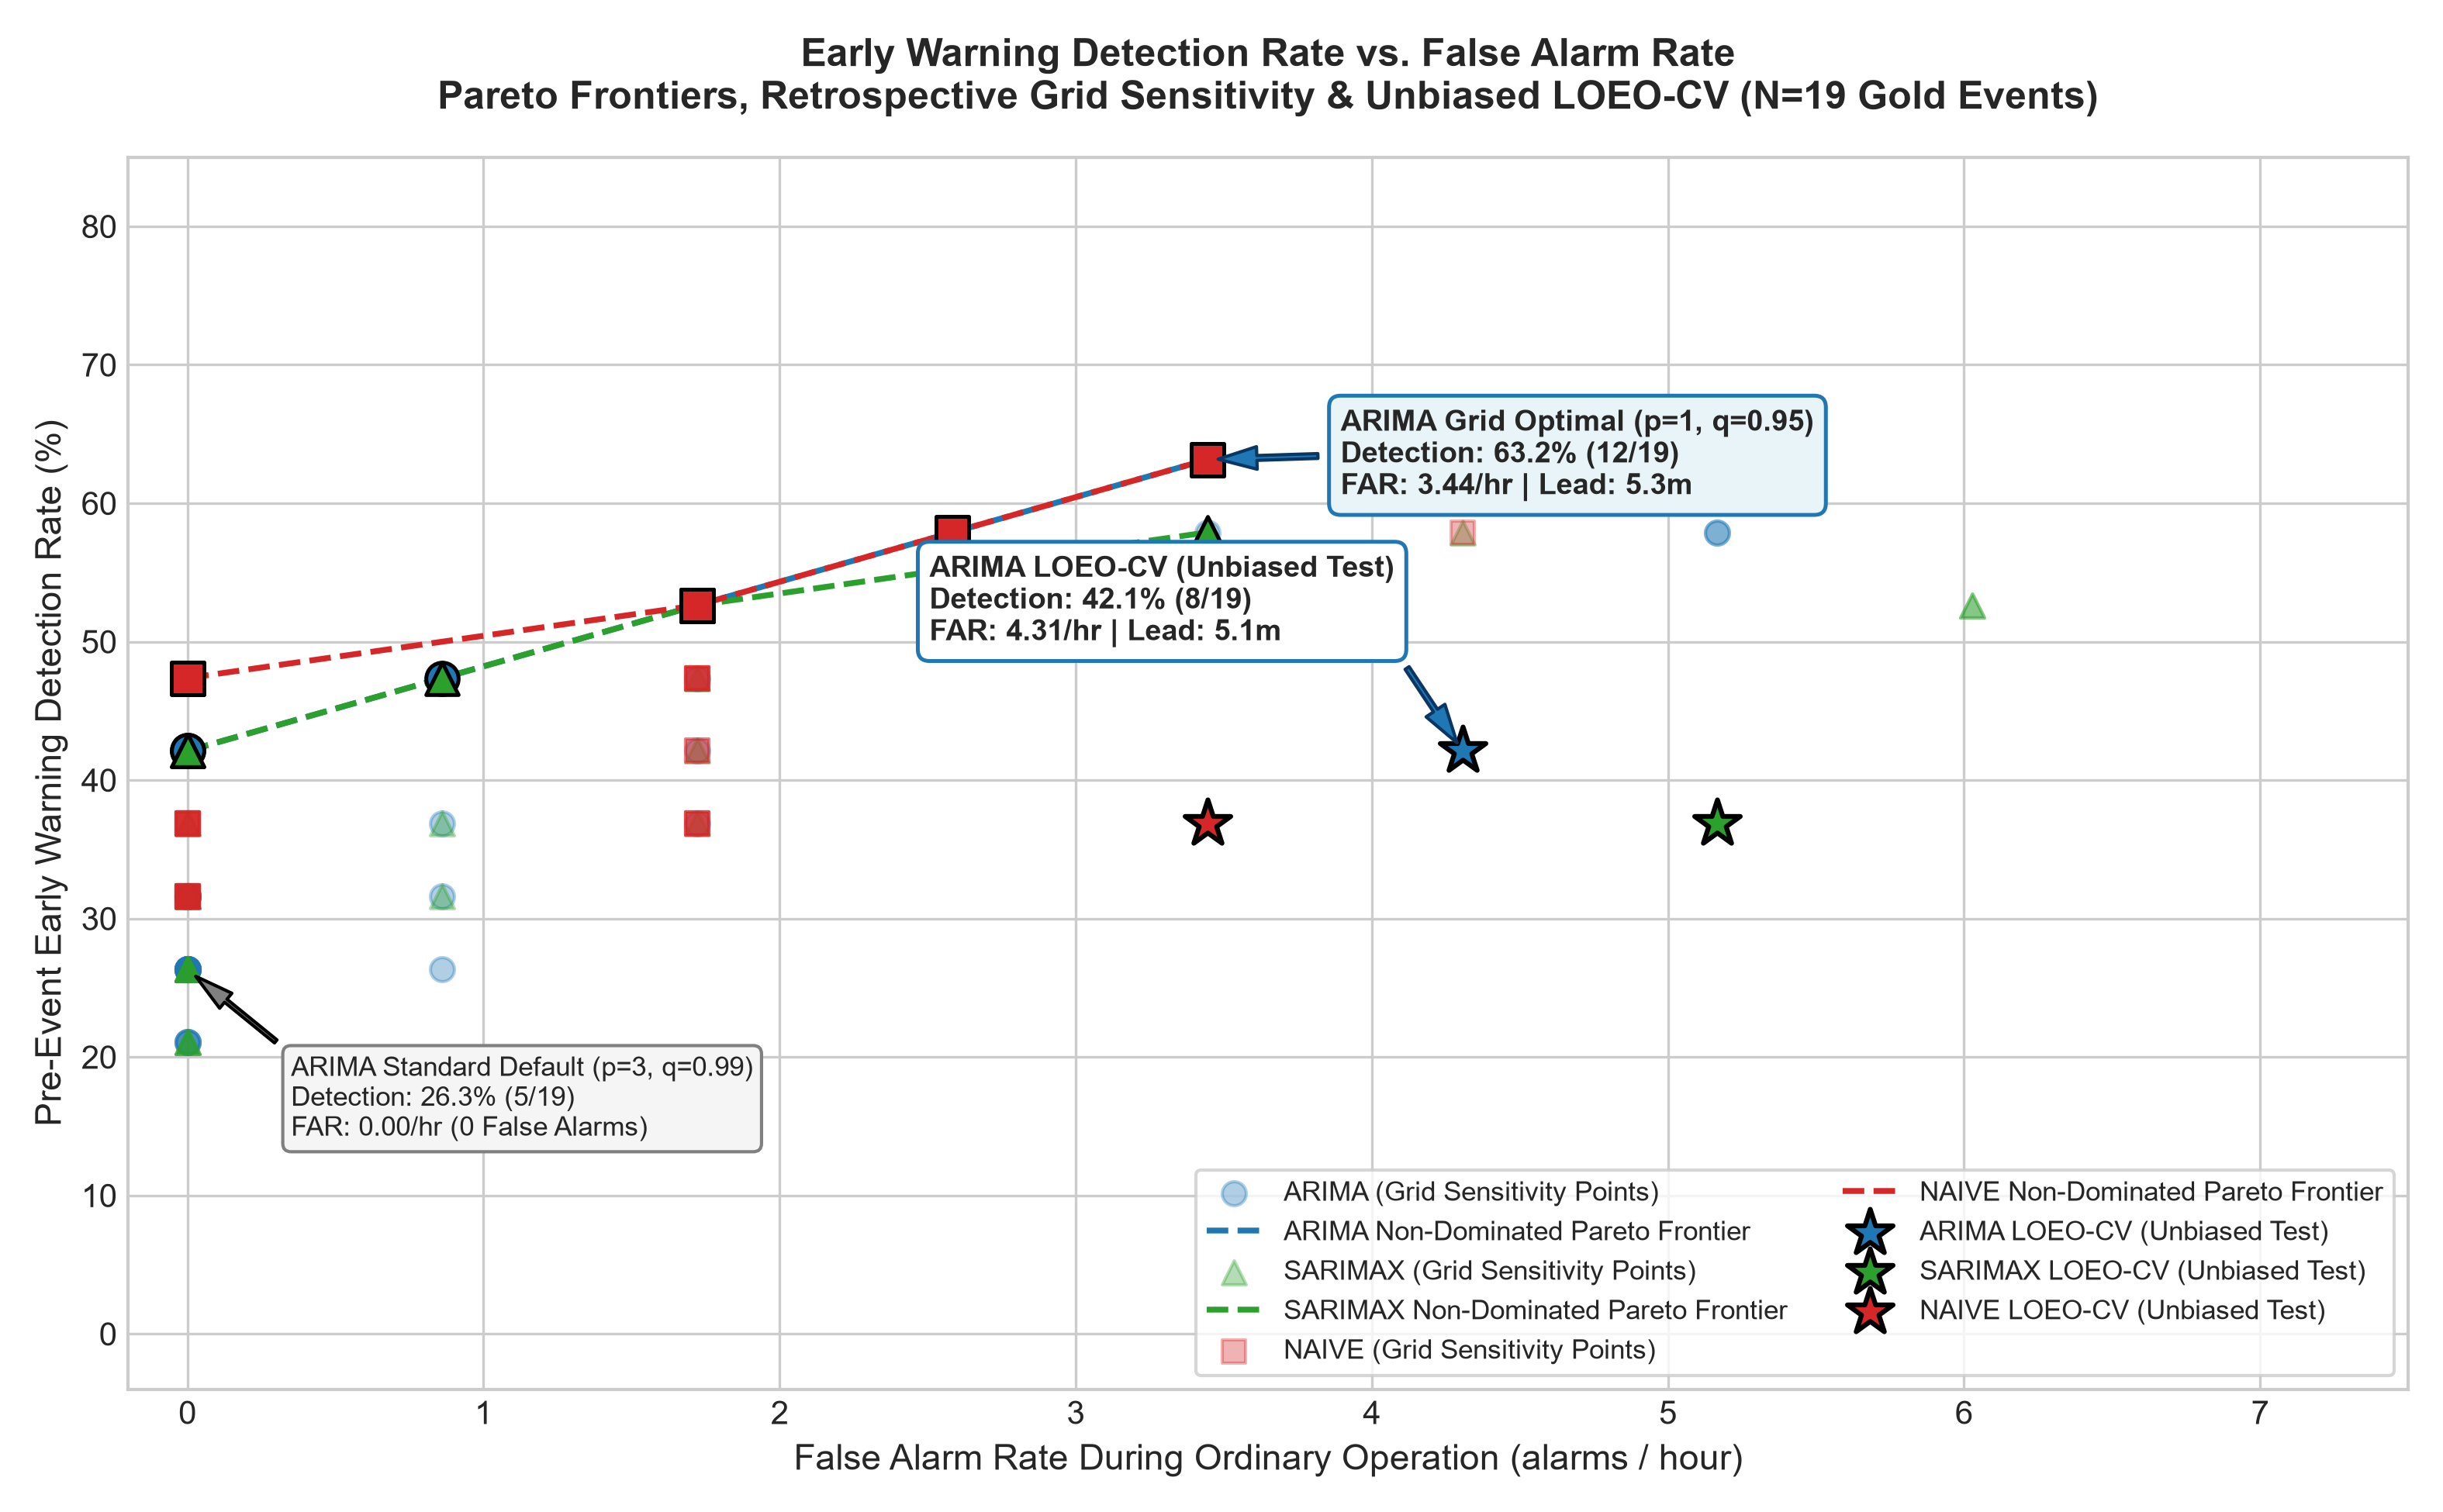

In [7]:
cv_df = pd.read_csv(PROJECT_ROOT / "results" / "metrics" / "optimization_loeo_cv_summary.csv")
print("=== UNBIASED LEAVE-ONE-EVENT-OUT CROSS-VALIDATION (LOEO-CV) ===")
sub_cv = cv_df[['model', 'unbiased_detection_rate', 'early_hits', 'total_events', 'unbiased_mean_lead_minutes', 'false_alarm_rate_per_hour', 'total_false_alarms']].copy()
sub_cv['unbiased_detection_rate'] = sub_cv['unbiased_detection_rate'] * 100
sub_cv.columns = ['Model', 'Detection Rate (%)', 'Early Hits', 'Total Events', 'Mean Lead (min)', 'FAR (/hr)', 'Total FA']
display(sub_cv.round(2))

opt_grid = pd.read_csv(PROJECT_ROOT / "results" / "metrics" / "optimization_grid_summary.csv")
print("\n=== RETROSPECTIVE GRID SENSITIVITY CEILING (p=1, q=0.95) ===")
sub_p1 = opt_grid[(opt_grid['persistence'] == 1) & (opt_grid['quantile'] == 0.95)][['model', 'early_detection_rate', 'early_hits', 'total_eligible_events', 'mean_lead_minutes', 'false_alarm_rate_per_hour']].copy()
sub_p1['early_detection_rate'] = sub_p1['early_detection_rate'] * 100
sub_p1.columns = ['Model', 'Early Detection Rate (%)', 'Early Hits', 'Total Events', 'Mean Lead (min)', 'FAR (/hr)']
display(sub_p1.round(2))

opt_ewma = pd.read_csv(PROJECT_ROOT / "results" / "metrics" / "optimization_ewma_summary.csv")
print("\n=== EWMA FILTERED RESIDUALS (lambda=0.3, q=0.975) ===")
sub_ewma = opt_ewma[(opt_ewma['lambda'] == 0.3) & (opt_ewma['quantile'] == 0.975)][['model', 'early_detection_rate', 'early_hits', 'total_eligible_events', 'mean_lead_minutes', 'false_alarm_rate_per_hour']].copy()
sub_ewma['early_detection_rate'] = sub_ewma['early_detection_rate'] * 100
sub_ewma.columns = ['Model', 'Early Detection Rate (%)', 'Early Hits', 'Total Events', 'Mean Lead (min)', 'FAR (/hr)']
display(sub_ewma.round(2))

from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / "results" / "figures" / "warning_optimization_pareto.png")))

## 9. Audited v2 Benchmark Reconciliation: Protocol 1 vs. Protocol 2

Following an independent scientific audit, two distinct evaluation protocols were implemented and compared:
- **Protocol 1 (Prospective Within-Event Split):** Fits models on an event's historical normal operation ($T < T_{\text{calib}}$), calibrates thresholds on its well-specific calibration window, and tests on holdout.
- **Protocol 2 (Genuine Cross-Well LOEO-CV):** Holds out the entire event $k$. Calibration thresholds are derived strictly from pooled normal data of the remaining 18 training wells. The held-out well contributes nothing to fitting or calibration.

### Matched Realized FAR Comparison (Operational Ceiling $\le 0.75\text{ FA/hr}$):
Evaluating detectors at matched realized nuisance-alarm levels ensures an unbiased scientific comparison.

=== AUDITED v2 MATCHED REALIZED FAR COMPARISON (N=19 Gold Events, 5 Wells) ===


,Model,P1 Det,P1 Lead (Mean/Med),P1 FAR,P2 Det (LOEO),P2 Lead (Mean/Med),P2 FAR,P3 Det (LOWO),P3 Lead (Mean/Med),P3 FAR,Budget Met?
0,sarimax,36.8%,4.0m / 4.3m,0.25,63.2%,4.8m / 4.8m,0.50,73.7%,5.2m / 5.8m,0.75,True
1,ac_0.85,47.4%,3.3m / 3.5m,0.50,63.2%,5.2m / 5.4m,0.50,73.7%,5.9m / 6.4m,1.01,True
2,ac_0.7,57.9%,2.8m / 2.5m,0.75,52.6%,4.7m / 4.4m,0.75,63.2%,3.4m / 2.4m,0.50,True
3,ac_0.5,68.4%,4.2m / 4.3m,0.75,63.2%,4.0m / 3.2m,0.50,63.2%,4.0m / 3.2m,0.50,True
4,arima,31.6%,2.5m / 1.5m,0.25,57.9%,5.2m / 5.2m,0.50,68.4%,5.7m / 6.3m,0.75,True
5,naive,47.4%,4.5m / 4.5m,1.01,47.4%,2.3m / 2.2m,1.01,57.9%,4.2m / 4.5m,1.01,False
6,lof,57.9%,4.6m / 4.8m,1.51,57.9%,4.5m / 4.8m,1.51,57.9%,4.5m / 4.8m,1.51,False


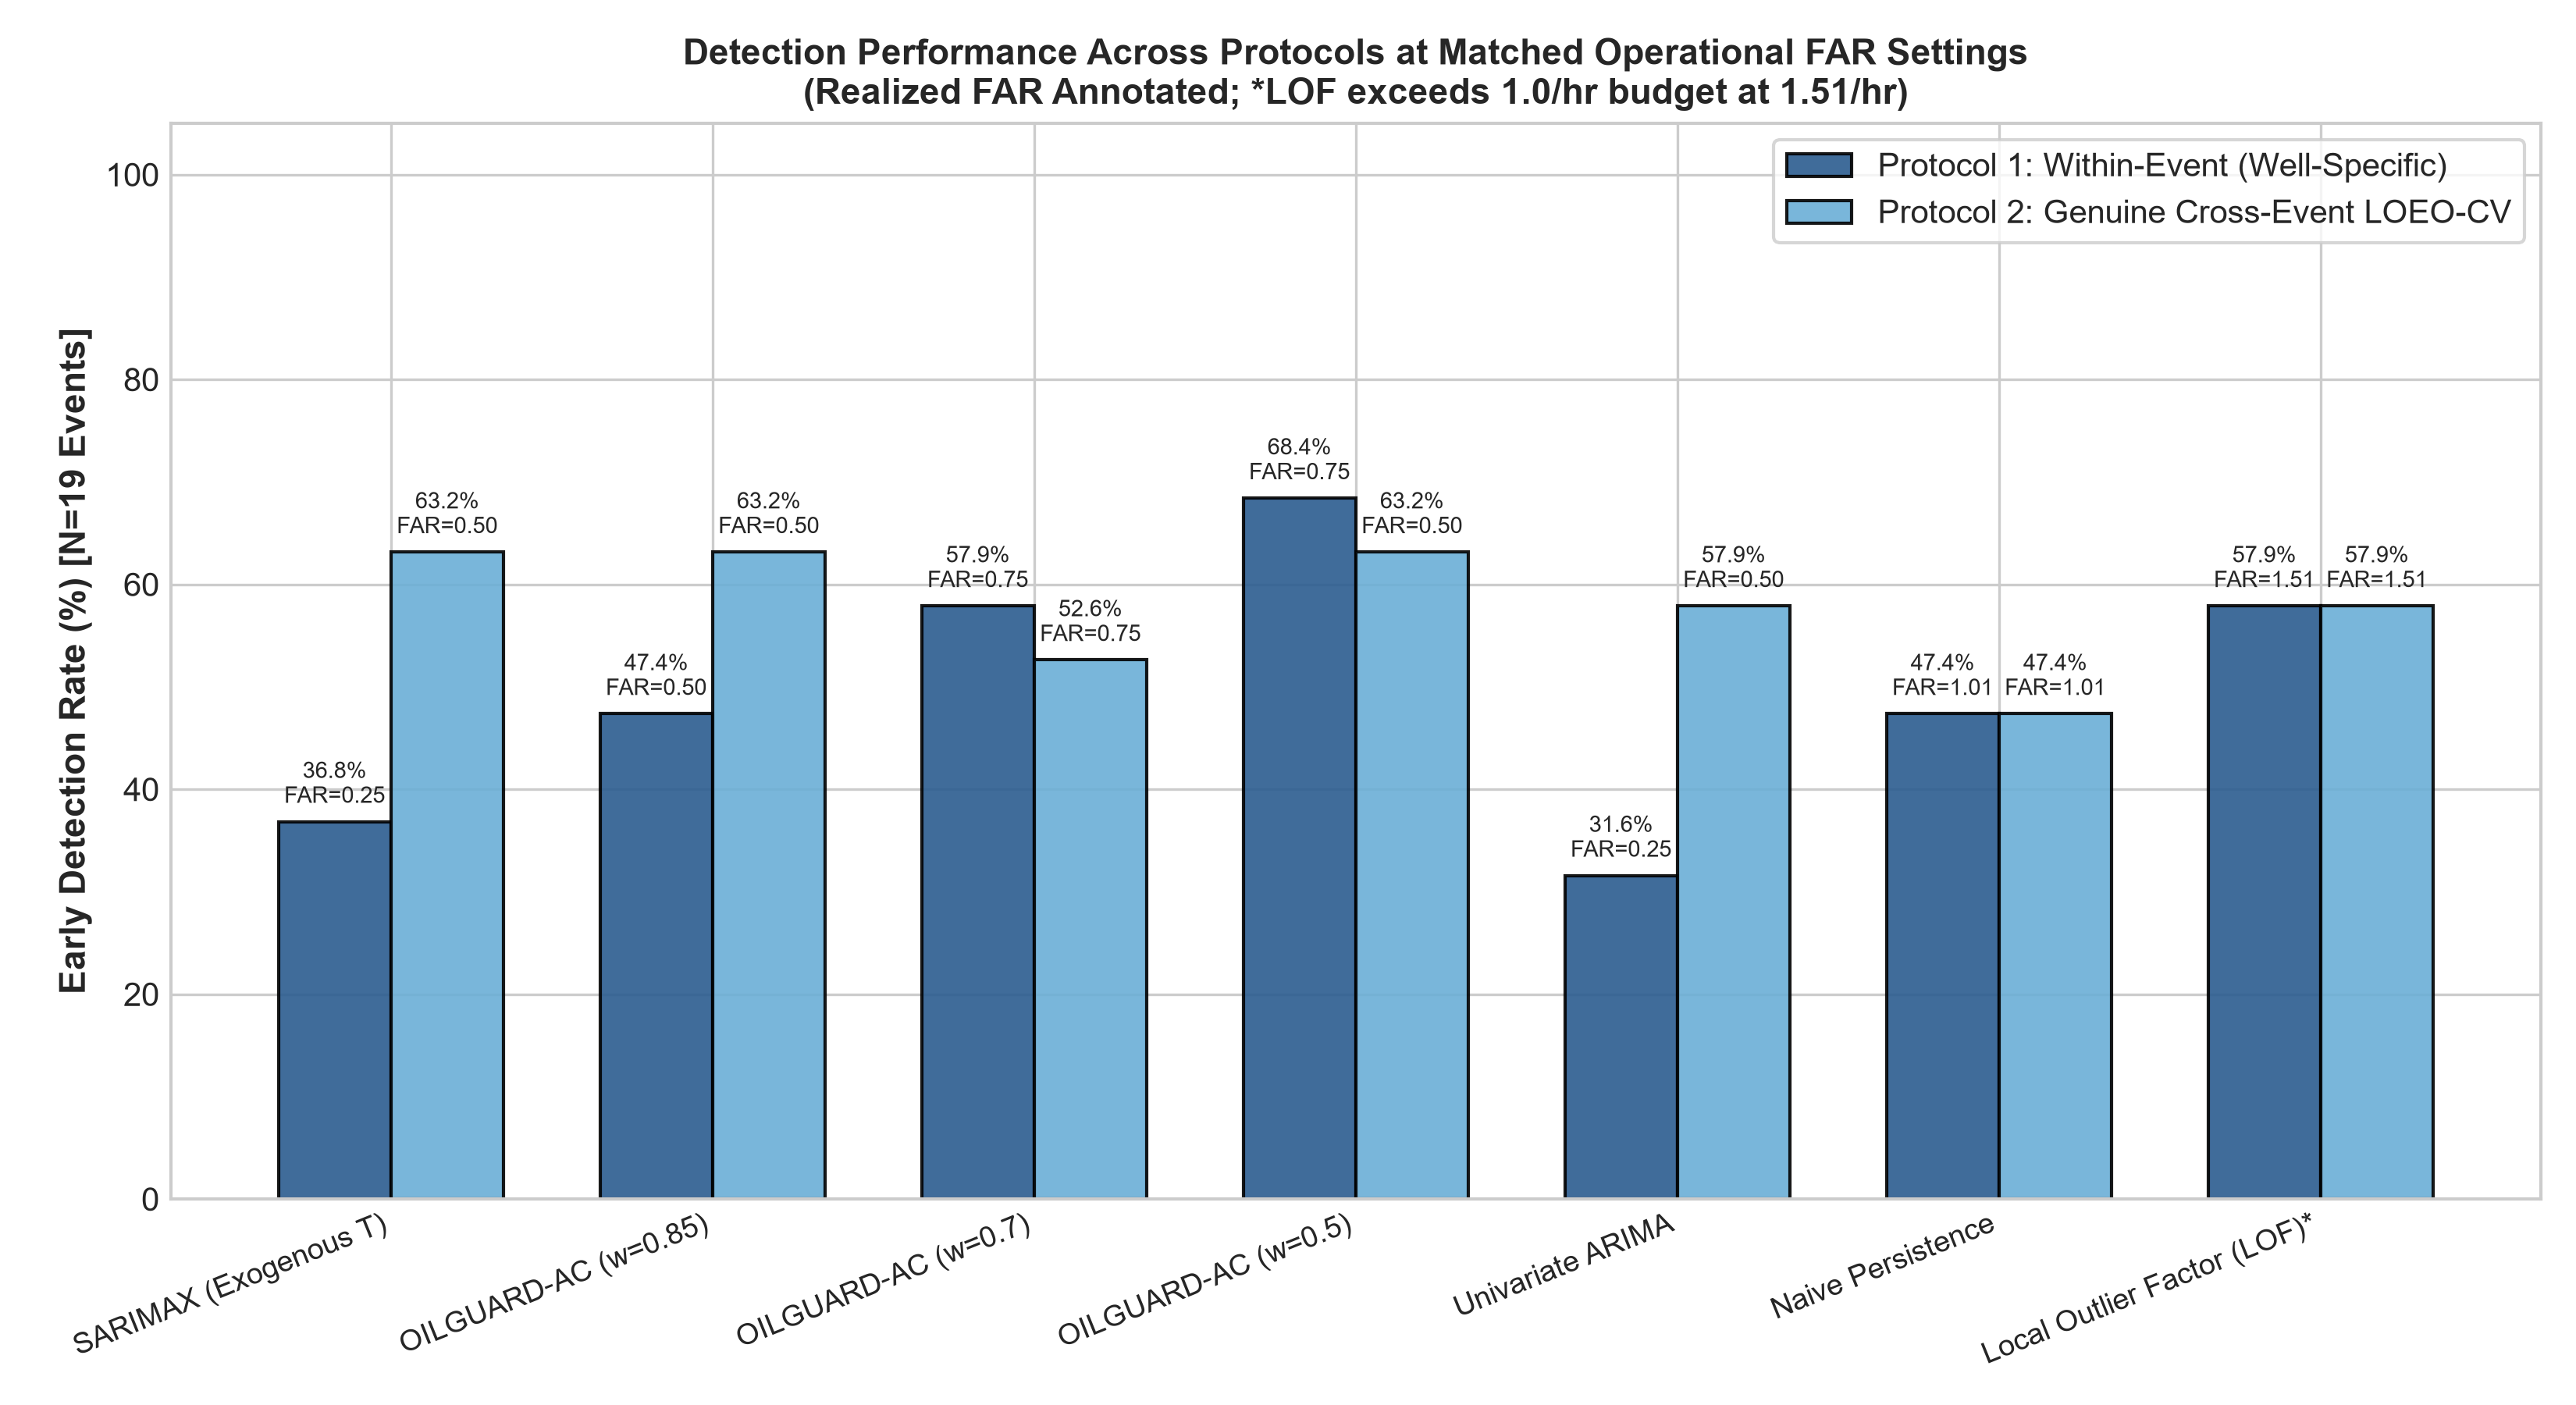

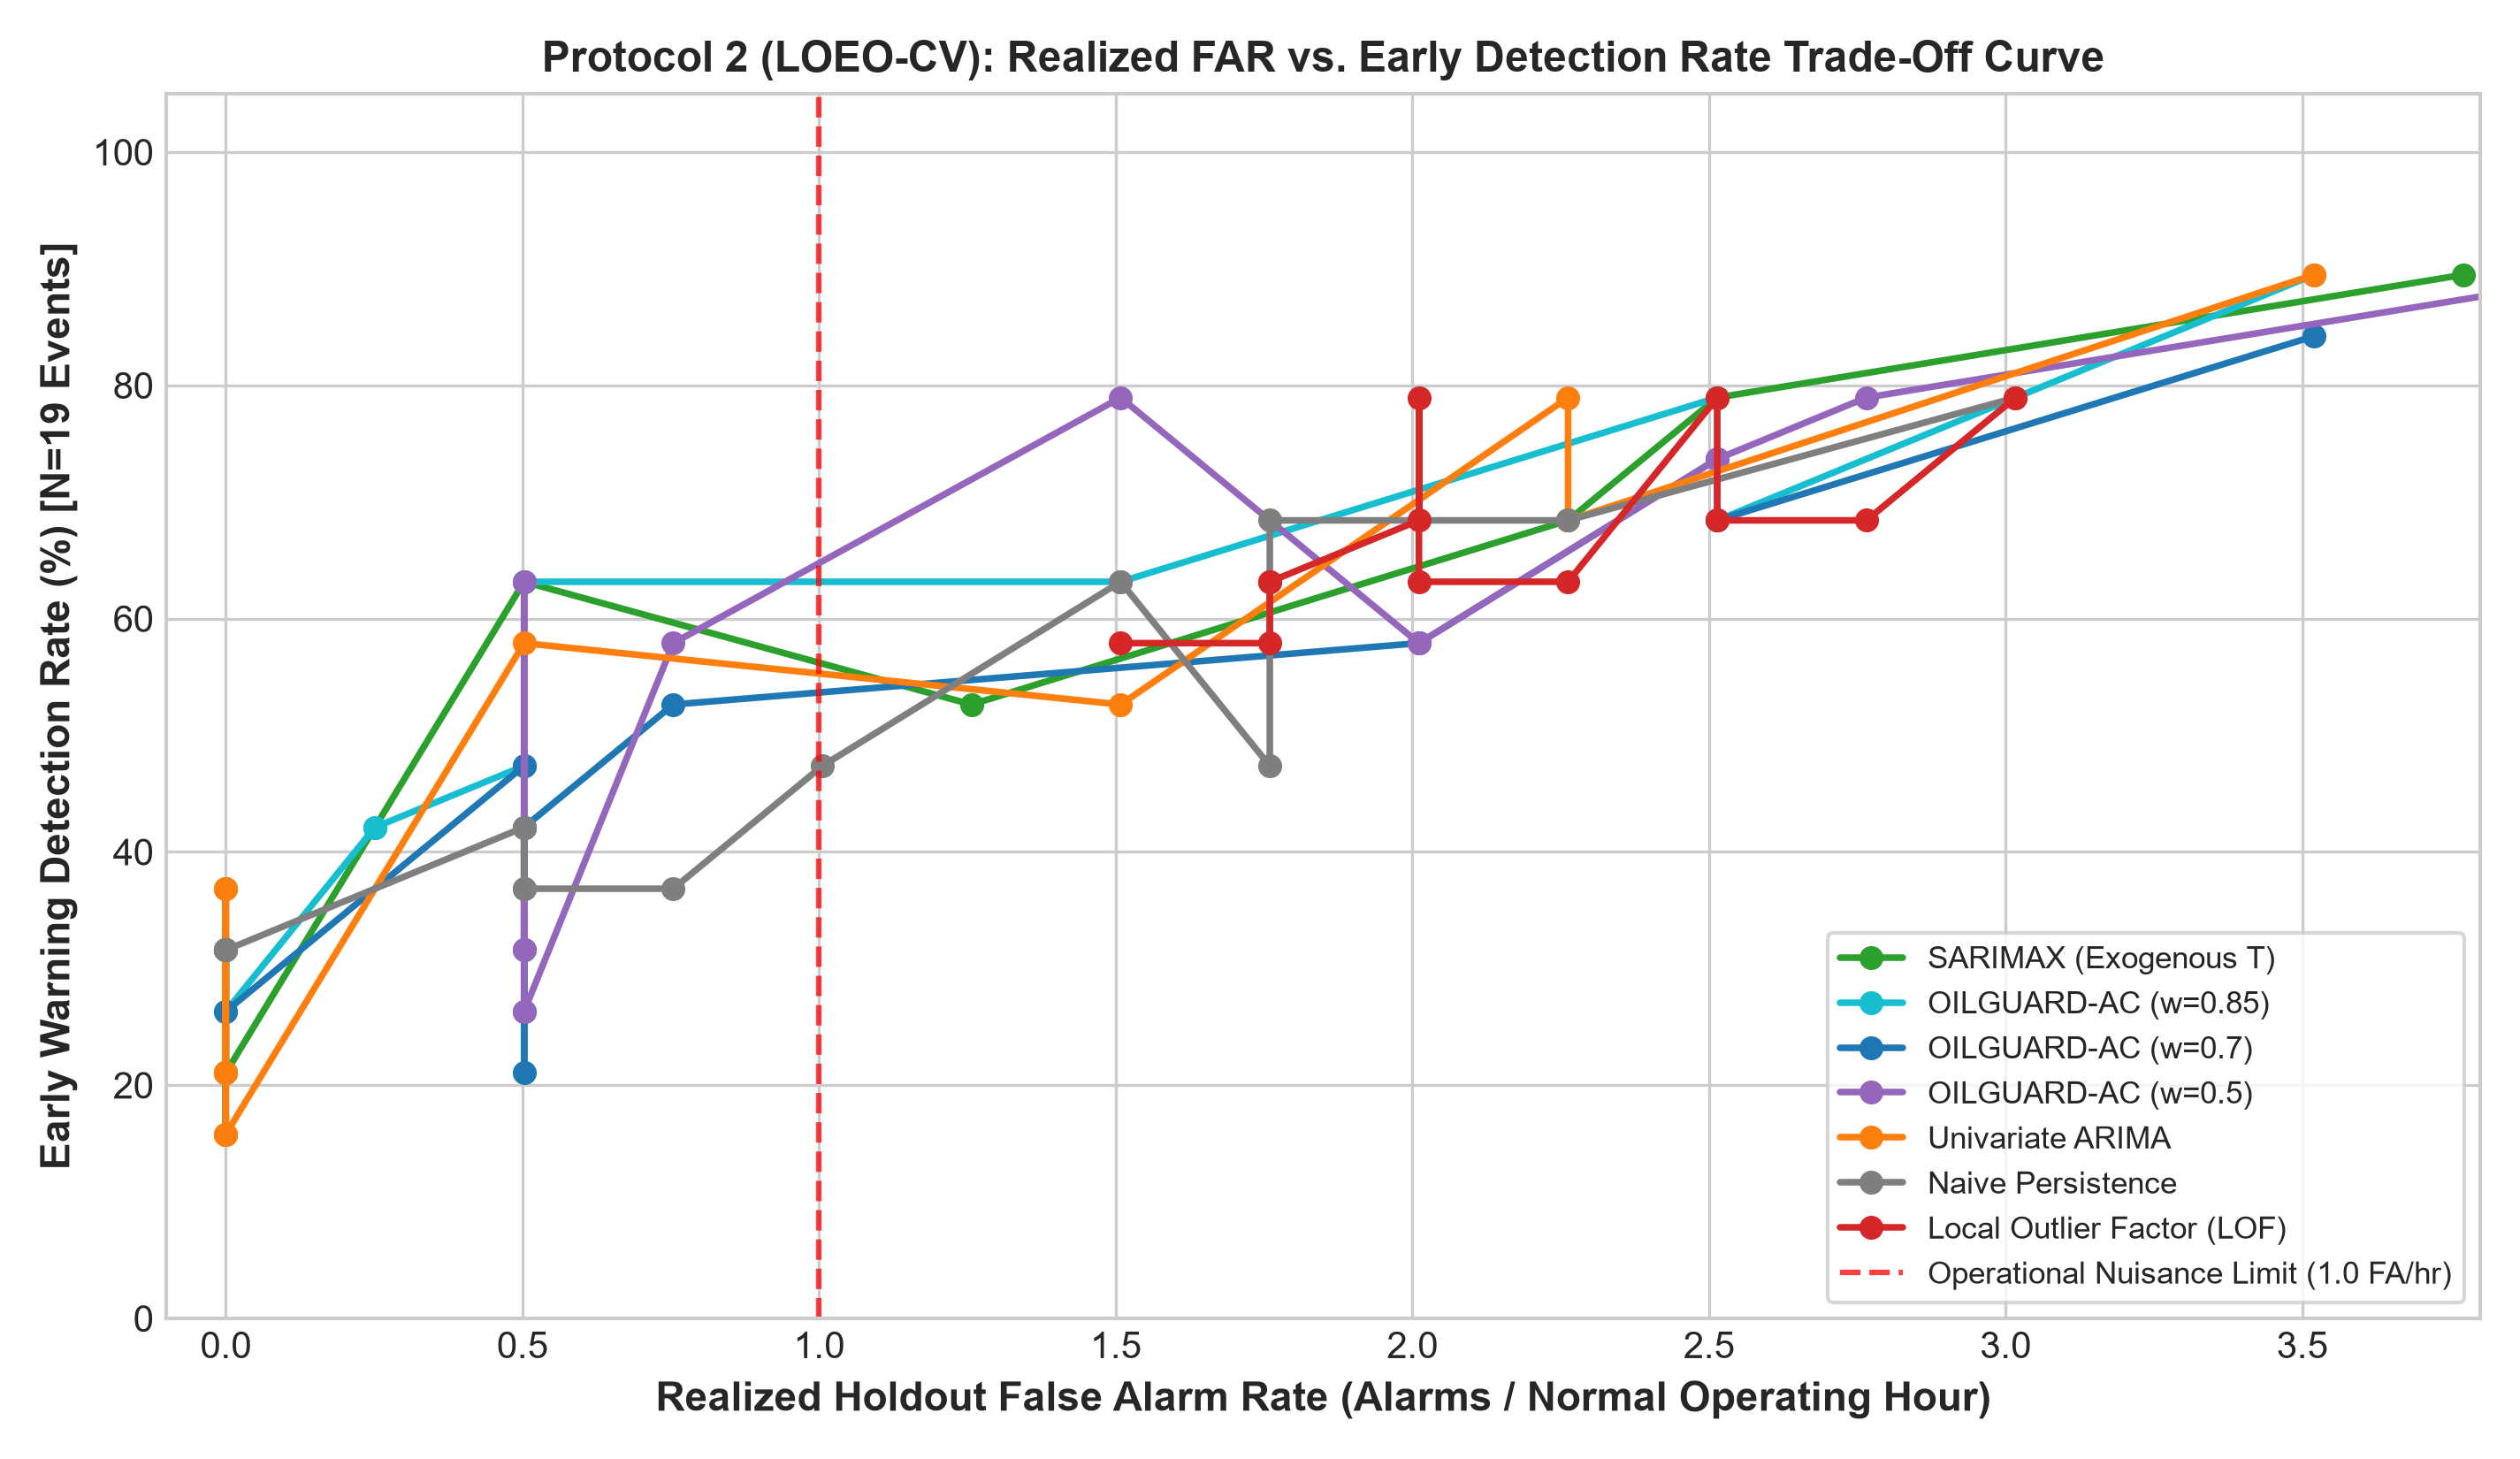

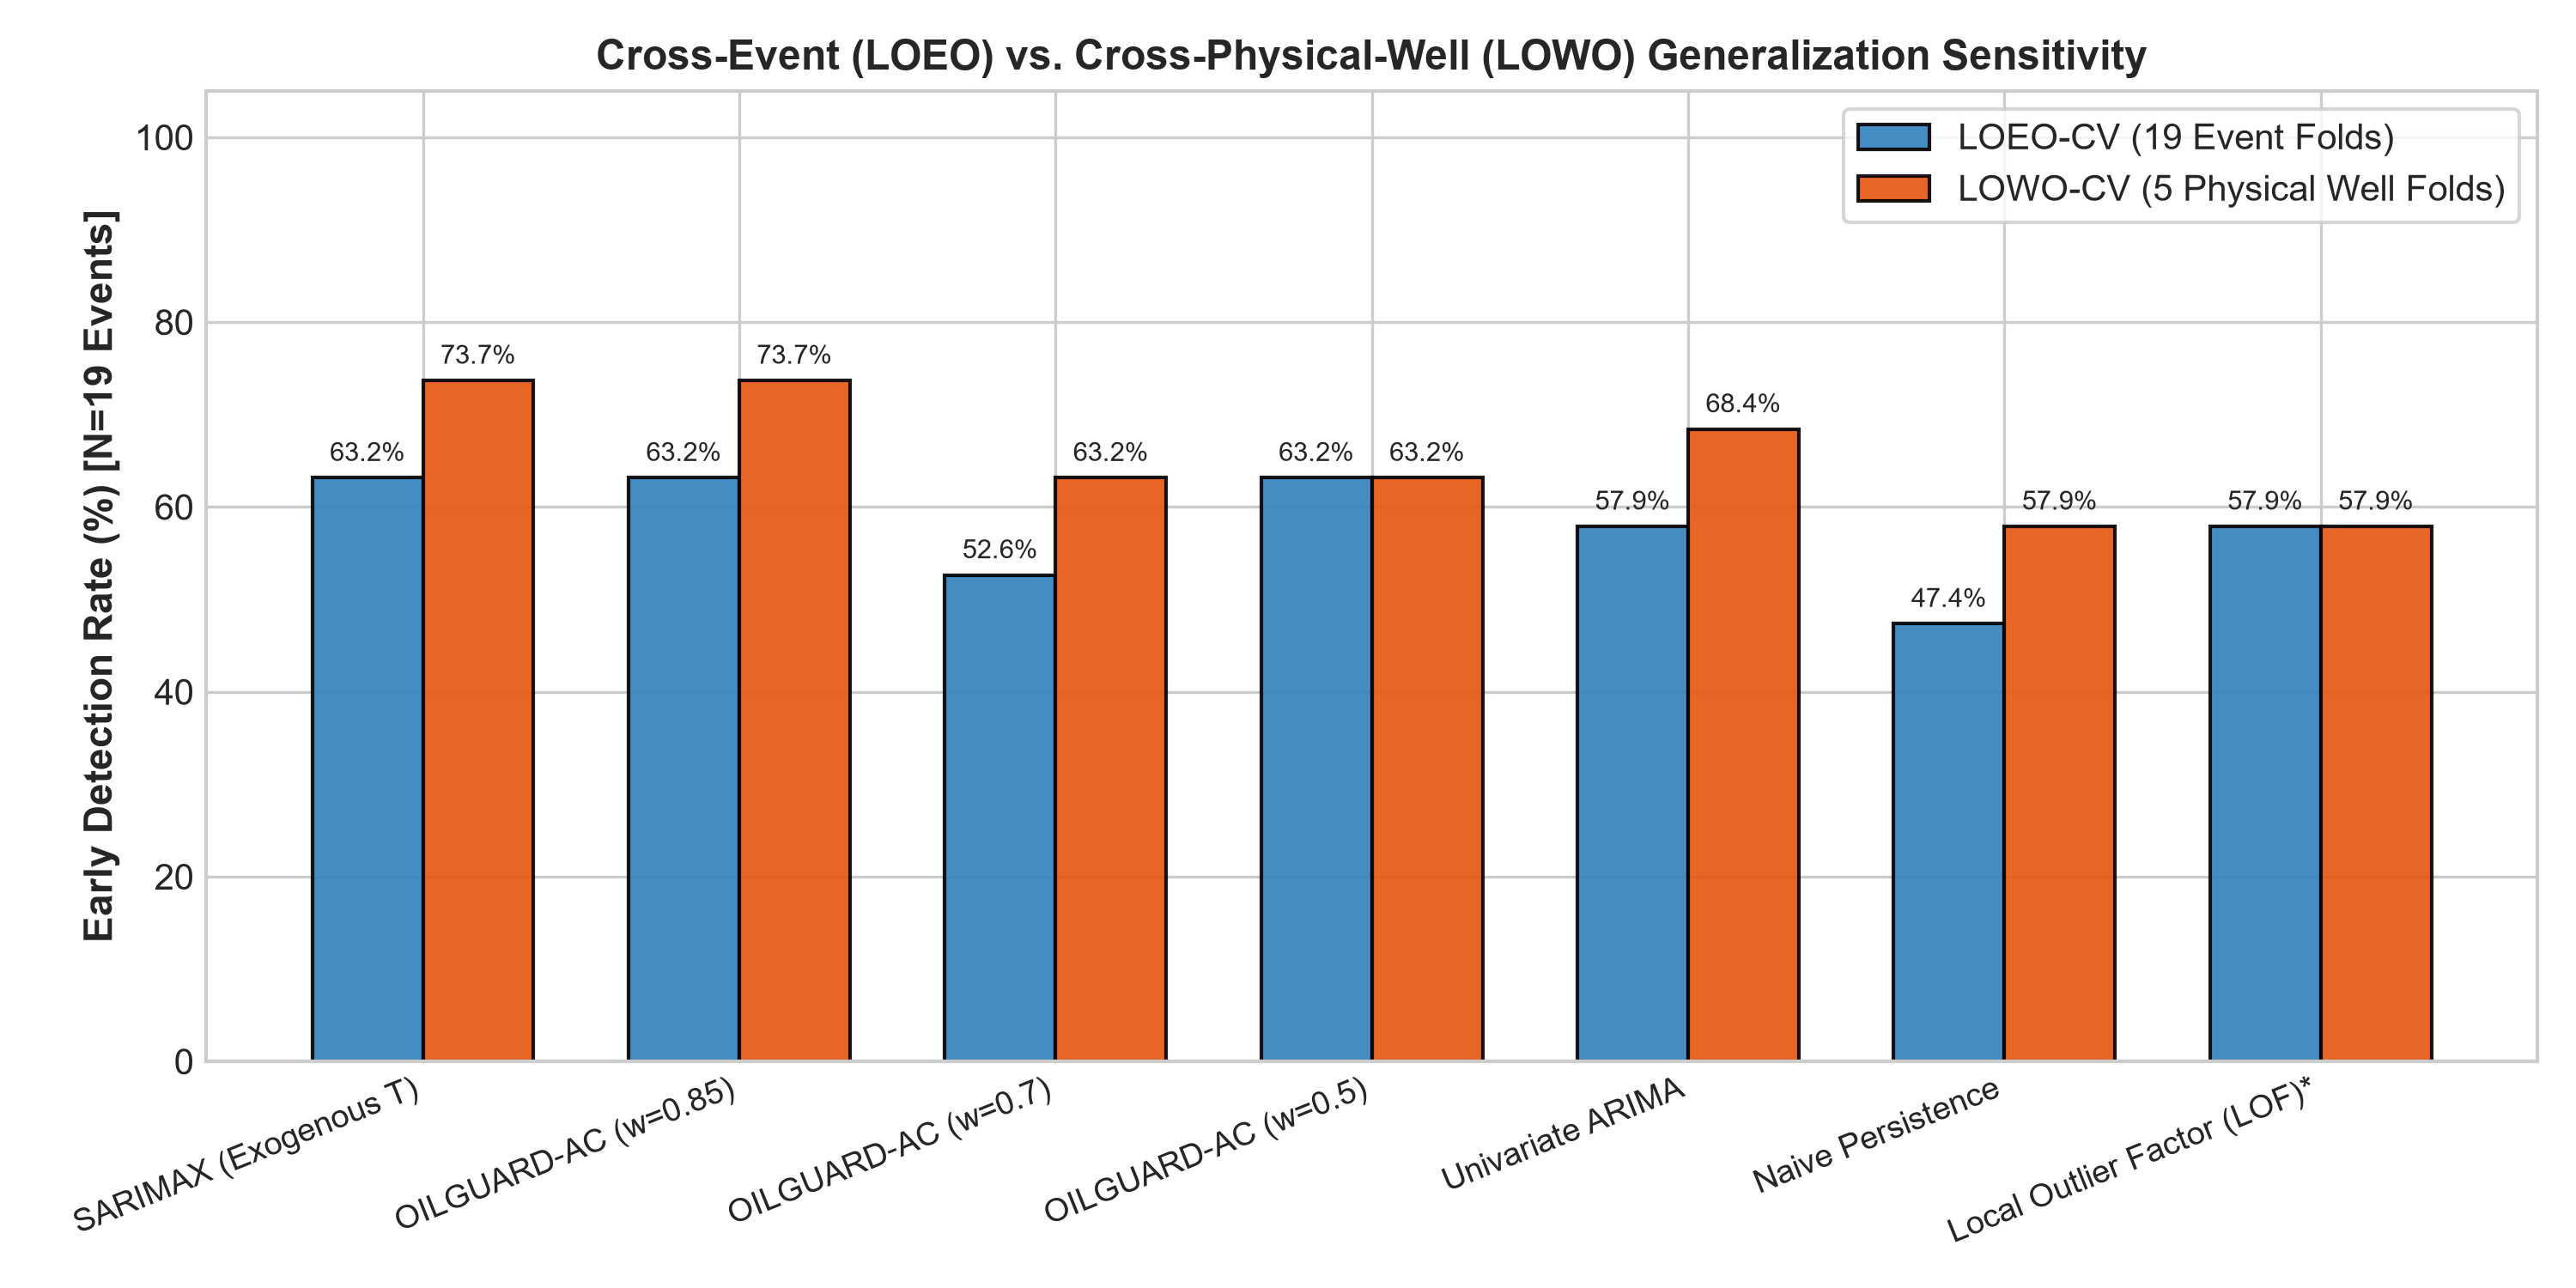

In [8]:
matched_df = pd.read_csv(PROJECT_ROOT / "results" / "audited_v2" / "metrics" / "matched_far_comparison.csv")
print("=== AUDITED v2 MATCHED REALIZED FAR COMPARISON (N=19 Gold Events, 5 Wells) ===")
disp = matched_df[['model', 'p1_detection_rate', 'p1_mean_lead', 'p1_med_lead', 'p1_realized_far',
                    'p2_detection_rate', 'p2_mean_lead', 'p2_med_lead', 'p2_realized_far',
                    'p3_detection_rate', 'p3_mean_lead', 'p3_med_lead', 'p3_realized_far', 'p2_meets_1.0_budget']].copy()

disp['p1_detection_rate'] = (disp['p1_detection_rate'] * 100).round(1).astype(str) + "%"
disp['p1_lead'] = disp['p1_mean_lead'].round(1).astype(str) + "m / " + disp['p1_med_lead'].round(1).astype(str) + "m"
disp['p1_realized_far'] = disp['p1_realized_far'].round(2)

disp['p2_detection_rate'] = (disp['p2_detection_rate'] * 100).round(1).astype(str) + "%"
disp['p2_lead'] = disp['p2_mean_lead'].round(1).astype(str) + "m / " + disp['p2_med_lead'].round(1).astype(str) + "m"
disp['p2_realized_far'] = disp['p2_realized_far'].round(2)

disp['p3_detection_rate'] = (disp['p3_detection_rate'] * 100).round(1).astype(str) + "%"
disp['p3_lead'] = disp['p3_mean_lead'].round(1).astype(str) + "m / " + disp['p3_med_lead'].round(1).astype(str) + "m"
disp['p3_realized_far'] = disp['p3_realized_far'].round(2)

table_out = disp[['model', 'p1_detection_rate', 'p1_lead', 'p1_realized_far',
                  'p2_detection_rate', 'p2_lead', 'p2_realized_far',
                  'p3_detection_rate', 'p3_lead', 'p3_realized_far', 'p2_meets_1.0_budget']]
table_out.columns = ['Model', 'P1 Det', 'P1 Lead (Mean/Med)', 'P1 FAR',
                     'P2 Det (LOEO)', 'P2 Lead (Mean/Med)', 'P2 FAR',
                     'P3 Det (LOWO)', 'P3 Lead (Mean/Med)', 'P3 FAR', 'Budget Met?']
display(table_out)

from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / "results" / "audited_v2" / "figures" / "protocol_comparison.png")))
display(Image(filename=str(PROJECT_ROOT / "results" / "audited_v2" / "figures" / "matched_far_tradeoff.png")))
display(Image(filename=str(PROJECT_ROOT / "results" / "audited_v2" / "figures" / "loeo_vs_lowo_comparison.png")))

## 10. Scientific Takeaways & Qualified Engineering Conclusions

1. **Dynamic Regression vs. Post-Hoc Heuristic Fusion:**
   - In cross-well LOEO-CV (Protocol 2), **SARIMAX (exogenous temperature)** and **balanced OILGUARD-AC ($w=0.5$)** both achieve the highest detection rate (**63.2%**, 12/19 events) at **0.50 FA/hr** (2 false alarms across 3.98 holdout hours).
   - Higher temperature weighting ($w=0.7$, 52.6% detection) degrades performance because downhole thermal inertia causes temperature deviations to lag acoustic pressure drops during incipient throttling.
2. **Failure of Non-Forecasting Density Baselines (LOF):**
   - Local Outlier Factor (LOF) achieves 57.9% detection but incurs a severe false-alarm penalty (**1.51 FA/hr**, 6 false alarms), completely violating the operational nuisance budget.
   - Because normal baseline pressure varies from 8.9 to 21.0 MPa across different offshore wells, density-based distance methods mistake wellhead pressure variations for anomalies.
3. **Calibration FAR vs. Realized Holdout FAR:**
   - Short calibration slices ($H_{	ext{calib}} < 0.5	ext{ h}$) cannot guarantee holdout compliance. Event-pooled cross-well calibration (Protocol 2) stabilizes threshold selection across wells.
4. **Qualified Operational Lead Time:**
   - The detected ~4 to 5 minutes of early warning represents an experimental finding under historical Petrobras 3W data, providing an actionable diagnostic window for control-room operators. Validation in high-fidelity multiphase transient simulators (e.g., OLGA) remains essential future work before field commissioning.